# 02 - Modeling experiments

**Issues:** #7 (preprocessing pipeline), #8 (baseline), #9 (feature engineering), #10 (model comparison), #11 (class imbalance) and #13 (hyperparameter tuning). Issue #12 (experiment tracking with MLflow, optional) is not done.

**Rules:** only the training and validation sets are used here; the test set stays untouched until the final evaluation (#20). Reusable code lives in `src/`; this notebook imports it.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.clean import load_clean_split
from src.features.preprocessing import FEATURES, build_preprocessor, get_xy
from src.features.engineering import ENGINEERED_FEATURES, SELECTED_DROP, SELECTED_ENGINEERED
from src.models.baseline import build_baseline
from src.models.imbalance import IMBALANCE_STRATEGIES, build_imbalance_model
from src.models.tuning import SPACE, build_tuned_model, load_best_params
from src.models.zoo import MODEL_NAMES, build_model
from src.models.cv import (
    CV_METRICS,
    N_SPLITS,
    RANDOM_STATE,
    cross_validate_model,
    cv_comparison_table,
    cv_table_to_markdown,
    paired_gain,
    summarize,
)
from src.models.evaluate import classification_metrics, comparison_to_markdown, precision_at_recall, update_comparison_table

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay, precision_score, recall_score

sns.set_theme(style="whitegrid")
REPORTS = ROOT / "reports"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Preprocessing pipeline (issue #7)

In [2]:
train = load_clean_split("train")   # cleaning rule from src/data/clean.py already applied
val = load_clean_split("val")
X_train, y_train = get_xy(train)
X_val, y_val = get_xy(val)
print(f"train: {X_train.shape} | validation: {X_val.shape}")
print(f"features used ({len(FEATURES)}): {FEATURES}")

train: (19443, 11) | validation: (6482, 11)
features used (11): ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_grade', 'cb_person_default_on_file', 'person_home_ownership', 'loan_intent']


### Tree-based variant
Raw numeric scales are kept (trees are scale-invariant). The pipeline is **fitted on the training set only**, then applied to validation.

In [3]:
tree_pipe = build_preprocessor("tree")
Xt_train = tree_pipe.fit_transform(X_train)
Xt_val = tree_pipe.transform(X_val)

print(f"output shape: train {Xt_train.shape} | validation {Xt_val.shape}")
print(f"missing values after transform: train {int(Xt_train.isna().sum().sum())} | validation {int(Xt_val.isna().sum().sum())}")
print(f"same columns in train and validation: {list(Xt_train.columns) == list(Xt_val.columns)}")
print()
print(list(Xt_train.columns))

output shape: train (19443, 20) | validation (6482, 20)
missing values after transform: train 0 | validation 0
same columns in train and validation: True

['person_income', 'person_emp_length', 'person_emp_length_missing', 'person_age', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_grade', 'cb_person_default_on_file', 'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']


### What the pipeline learned (from the training set)

In [4]:
imputer = tree_pipe.named_steps["rate_imputer"]
emp_median = tree_pipe.named_steps["columns"].named_transformers_["emp_length"].named_steps["impute"].statistics_[0]

learned = pd.Series(imputer.group_medians_, name="median loan_int_rate").round(2).to_frame()
display(learned)
print(f"global median loan_int_rate (fallback for unseen grades): {imputer.global_median_:.2f}")
print(f"median person_emp_length: {emp_median:.1f}")

# The learned medians must equal a direct computation on the training set alone.
direct = X_train.groupby("loan_grade")["loan_int_rate"].median()
assert all(abs(direct[g] - m) < 1e-12 for g, m in imputer.group_medians_.items())
print("Check passed: grade medians come from the training set only.")

,median loan_int_rate
A,7.49
B,10.99
C,13.48
D,15.31
E,16.77
F,18.43
G,20.11


global median loan_int_rate (fallback for unseen grades): 10.99
median person_emp_length: 4.0
Check passed: grade medians come from the training set only.


### Missing-value indicator for `person_emp_length`

In [5]:
for name, raw, out in (("train", X_train, Xt_train), ("validation", X_val, Xt_val)):
    print(f"{name:10s} raw missing share = {raw['person_emp_length'].isna().mean():.4f} | indicator share = {out['person_emp_length_missing'].mean():.4f}")

train      raw missing share = 0.0278 | indicator share = 0.0278
validation raw missing share = 0.0287 | indicator share = 0.0287


### Linear variant
`person_income` goes through `log1p`, and all numeric features are standardized. Means and standard deviations are those of the **training** set, so validation values are close to, but not exactly, 0 and 1.

In [6]:
lin_pipe = build_preprocessor("linear")
Xl_train = lin_pipe.fit_transform(X_train)
Xl_val = lin_pipe.transform(X_val)

numeric = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
summary = pd.concat(
    {"train": Xl_train[numeric].agg(["mean", "std"]).T, "validation": Xl_val[numeric].agg(["mean", "std"]).T},
    axis=1,
).round(3)
display(summary)

train      validation       
                            mean  std       mean    std
person_age                   0.0  1.0     -0.010  1.005
person_income                0.0  1.0     -0.014  0.994
person_emp_length           -0.0  1.0     -0.014  0.987
loan_amnt                   -0.0  1.0      0.001  0.999
loan_int_rate                0.0  1.0     -0.001  1.006
loan_percent_income         -0.0  1.0      0.015  0.996
cb_person_cred_hist_length  -0.0  1.0      0.002  0.994

### Summary

- The pipeline has **20 output columns** (7 numeric, 1 missing-value indicator, 2 ordinal, 10 one-hot) and leaves no missing value.
- Imputation medians (interest rate by grade, employment length) are learned on the training set and reused unchanged on validation; a direct computation confirms it.
- Two variants share the same code: `tree` (raw scales) and `linear` (log income + standardization).
- Unknown grades raise an error, unknown home ownership or loan intent values are encoded as all zeros (see `tests/test_preprocessing.py`).
- The fitted pipeline can be saved with `save_preprocessor` and reloaded by the API.

## 2. Baseline: logistic regression (issue #8)

The reference every later model must beat: the `linear` preprocessing variant followed by a plain logistic regression (default regularization, no class weights). Class imbalance is handled in issue #11, not here.

Metrics are computed on the **validation set**. ROC AUC, PR AUC, KS and Brier score do not depend on a threshold. Recall and precision are shown at the default threshold of 0.5 only as a reference: the cost-optimal threshold is chosen in issue #16.

In [7]:
prevalence = y_train.mean()
print(f"default rate: train {prevalence:.4f} | validation {y_val.mean():.4f}")

# Reference without any model: the same probability for everyone (the training default rate).
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
dummy_scores = dummy.predict_proba(X_val)[:, 1]
dummy_metrics = classification_metrics(y_val, dummy_scores)

baseline = build_baseline().fit(X_train, y_train)
val_scores = baseline.predict_proba(X_val)[:, 1]
base_metrics = classification_metrics(y_val, val_scores)

metric_cols = ["roc_auc", "pr_auc", "ks", "brier", "recall", "precision"]
results = pd.DataFrame({"constant prior (no model)": dummy_metrics, "logistic regression": base_metrics}).T[metric_cols]
display(results.round(4))

default rate: train 0.2187 | validation 0.2188


,roc_auc,pr_auc,ks,brier,recall,precision
constant prior (no model),0.5000,0.2188,0.0000,0.1709,0.0000,0.0000
logistic regression,0.8767,0.7230,0.6107,0.1036,0.5437,0.7406


In [8]:
print(f"Confusion matrix at threshold 0.5 (validation, {len(y_val)} rows)")
cm = pd.DataFrame(
    [[base_metrics["tn"], base_metrics["fp"]], [base_metrics["fn"], base_metrics["tp"]]],
    index=["actual: no default", "actual: default"],
    columns=["predicted: no default", "predicted: default"],
)
display(cm)

Confusion matrix at threshold 0.5 (validation, 6482 rows)


,predicted: no default,predicted: default
actual: no default,4794,270
actual: default,647,771


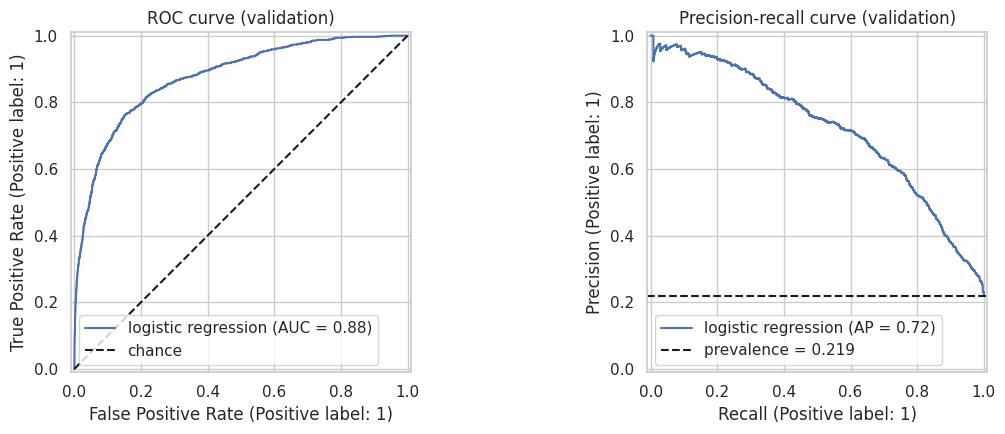

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_val, val_scores, name="logistic regression", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set_title("ROC curve (validation)")
axes[0].legend()
PrecisionRecallDisplay.from_predictions(y_val, val_scores, name="logistic regression", ax=axes[1])
axes[1].axhline(y_val.mean(), color="k", linestyle="--", label=f"prevalence = {y_val.mean():.3f}")
axes[1].set_title("Precision-recall curve (validation)")
axes[1].legend()
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "baseline_roc_pr.png", dpi=130, bbox_inches="tight")
plt.show()

In [10]:
names = baseline.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(baseline.named_steps["model"].coef_[0], index=names).sort_values()
print("Largest negative and positive coefficients. Read the sign only: binary/ordinal columns and standardized numeric columns are not on the same scale.")
display(pd.concat([coefs.head(5), coefs.tail(5)]).round(3).to_frame("coefficient"))

Largest negative and positive coefficients. Read the sign only: binary/ordinal columns and standardized numeric columns are not on the same scale.


,coefficient
person_home_ownership_OWN,-2.104
loan_intent_VENTURE,-1.048
loan_intent_EDUCATION,-0.791
person_income,-0.611
loan_intent_PERSONAL,-0.582
loan_intent_HOMEIMPROVEMENT,0.137
person_home_ownership_RENT,0.209
person_emp_length_missing,0.537
loan_percent_income,0.821
loan_grade,1.088


In [11]:
table = update_comparison_table(
    REPORTS / "model_comparison.csv", "constant prior (no model)", dummy_metrics,
    notes="same probability for everyone",
)
table = update_comparison_table(
    REPORTS / "model_comparison.csv", "logistic regression (baseline)", base_metrics,
    notes="linear preprocessing, default C=1, no class weights",
)
display(table)
print(comparison_to_markdown(table))

,model,split,roc_auc,pr_auc,ks,brier,recall,precision,threshold,notes
0,logistic + loan_to_income (replaces loan_perce...,validation,0.8779,0.7261,0.6089,0.1029,0.5501,0.7436,0.5,issue 9: recomputed ratio replaces the provide...
1,lightgbm (default settings),validation,0.9459,0.9049,0.7595,0.0514,0.7525,0.9544,0.5,"issue 10: chosen model, selected features (loa..."
2,"lightgbm (tuned, 40 Optuna trials)",validation,0.9479,0.9071,0.7648,0.0511,0.7496,0.9664,0.5,"issue 13: not adopted, gain within noise"
3,constant prior (no model),validation,0.5000,0.2188,0.0000,0.1709,0.0000,0.0000,0.5,same probability for everyone
4,logistic regression (baseline),validation,0.8767,0.7230,0.6107,0.1036,0.5437,0.7406,0.5,"linear preprocessing, default C=1, no class we..."


| Model | ROC AUC | PR AUC | KS | Brier | Recall | Precision |
|---|---|---|---|---|---|---|
| logistic + loan_to_income (replaces loan_percent_income) | 0.878 | 0.726 | 0.609 | 0.103 | 0.550 | 0.744 |
| lightgbm (default settings) | 0.946 | 0.905 | 0.759 | 0.051 | 0.752 | 0.954 |
| lightgbm (tuned, 40 Optuna trials) | 0.948 | 0.907 | 0.765 | 0.051 | 0.750 | 0.966 |
| constant prior (no model) | 0.500 | 0.219 | 0.000 | 0.171 | 0.000 | 0.000 |
| logistic regression (baseline) | 0.877 | 0.723 | 0.611 | 0.104 | 0.544 | 0.741 |


### Baseline summary (validation set, single split)

- **Ranking quality:** ROC AUC 0.877, PR AUC 0.723 (versus 0.219 for a constant prediction, about 3.3 times higher) and KS 0.611.
- **Probability quality:** Brier score 0.104, versus 0.171 for the constant prediction.
- **At the default threshold of 0.5:** 771 of the 1,418 defaults are caught (recall 54.4%) and 771 of the 1,041 flagged customers really default (precision 74.1%). 647 defaults are missed and 270 good customers are refused.
- **Hypothesis for issue #16:** since a missed default is assumed to cost about 5 times more than a refused good customer, a threshold below 0.5 will probably be cheaper. This is not quantified yet.
- **Signs of the coefficients** match the EDA: higher grade, higher loan-to-income and a missing employment length push the default probability up; higher income and home ownership push it down.
- **Limits:** one validation split and no confidence interval, so small differences between models must be confirmed with cross-validation (issue #10).

**To beat:** PR AUC 0.723, KS 0.611, ROC AUC 0.877.

## 3. Feature engineering (issue #9)

### Protocol (fixed before looking at any result)

- **Data:** the cleaned **training set only**, with 5-fold stratified cross-validation (same folds for every candidate, seed 42). Validation and test are not used to choose features.
- **Two model families**, because a gain for a linear model can vanish for trees: the logistic regression of the baseline, and a gradient boosting model (`HistGradientBoostingClassifier`, default settings, as a quick tree-based reference; the real model comparison is issue #10).
- **Candidates**, each added alone: `loan_to_income` (recomputed ratio), `rate_vs_grade_median` (rate minus the median rate of its grade), `cred_hist_to_age` (credit history length over age), `high_burden` (loan-to-income above 0.25, a threshold taken from the EDA). Also tested: `loan_to_income` **replacing** `loan_percent_income`, and all four together.
- **Metric:** PR AUC (KS is shown as a check). The gain is the paired fold-by-fold difference with the baseline.
- **Selection rule:** keep a candidate if its mean PR AUC gain is larger than the standard deviation of the paired differences **in at least one family**, and is not negative in **either** family.

In [12]:
X_tr, y_tr = X_train, y_train          # cleaned training set; validation is not touched in this section

def tree_model(**kw):
    return Pipeline([
        ("preprocess", build_preprocessor("tree", **kw)),
        ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ])

configs = {
    "baseline": dict(engineered=(), drop=()),
    "+ loan_to_income": dict(engineered=("loan_to_income",), drop=()),
    "loan_to_income replaces loan_percent_income": dict(engineered=("loan_to_income",), drop=("loan_percent_income",)),
    "+ rate_vs_grade_median": dict(engineered=("rate_vs_grade_median",), drop=()),
    "+ cred_hist_to_age": dict(engineered=("cred_hist_to_age",), drop=()),
    "+ high_burden": dict(engineered=("high_burden",), drop=()),
    "+ all four": dict(engineered=tuple(ENGINEERED_FEATURES), drop=()),
}
makers = {"logistic": lambda c: build_baseline(**c), "gradient boosting": lambda c: tree_model(**c)}

cv = {(fam, name): cross_validate_model(make(cfg), X_tr, y_tr) for fam, make in makers.items() for name, cfg in configs.items()}

for fam in makers:
    s = summarize(cv[(fam, "baseline")])
    print(f"{fam:18s} baseline (5-fold CV on train): PR AUC {s.loc['pr_auc','mean']:.4f} +/- {s.loc['pr_auc','std']:.4f} | KS {s.loc['ks','mean']:.4f} | ROC AUC {s.loc['roc_auc','mean']:.4f}")

logistic           baseline (5-fold CV on train): PR AUC 0.7060 +/- 0.0181 | KS 0.5809 | ROC AUC 0.8662
gradient boosting  baseline (5-fold CV on train): PR AUC 0.8918 +/- 0.0026 | KS 0.7381 | ROC AUC 0.9391


In [13]:
rows = []
for name in list(configs)[1:]:
    row = {"candidate": name}
    for fam in makers:
        g = paired_gain(cv[(fam, "baseline")], cv[(fam, name)], "pr_auc")
        k = paired_gain(cv[(fam, "baseline")], cv[(fam, name)], "ks")
        row.update({
            f"{fam}: dPR AUC": g["mean_gain"], f"{fam}: sd": g["std_gain"], f"{fam}: folds+": f"{g['folds_improved']}/{g['n_folds']}",
            f"{fam}: dKS": k["mean_gain"],
        })
    rows.append(row)
gains = pd.DataFrame(rows).set_index("candidate")
display(gains.round(4))

def passes_rule(name):
    g = {fam: paired_gain(cv[(fam, "baseline")], cv[(fam, name)], "pr_auc") for fam in makers}
    beats_noise = any(v["mean_gain"] > v["std_gain"] for v in g.values())
    never_harmful = all(v["mean_gain"] >= 0 for v in g.values())
    return beats_noise and never_harmful

passing = [n for n in list(configs)[1:] if passes_rule(n)]
print("Candidates passing the rule:", passing)

,logistic: dPR AUC,logistic: sd,logistic: folds+,logistic: dKS,gradient boosting: dPR AUC,gradient boosting: sd,gradient boosting: folds+,gradient boosting: dKS
candidate,,,,,,,,
+ loan_to_income,0.0151,0.0036,5/5,0.0086,0.0005,0.0024,3/5,0.0003
loan_to_income replaces loan_percent_income,0.0030,0.0007,5/5,0.0023,0.0006,0.0021,3/5,-0.0013
+ rate_vs_grade_median,0.0047,0.0040,5/5,0.0127,-0.0007,0.0016,2/5,-0.0040
+ cred_hist_to_age,0.0001,0.0006,3/5,0.0007,-0.0000,0.0017,3/5,-0.0020
+ high_burden,0.0022,0.0034,4/5,0.0076,0.0000,0.0000,0/5,0.0000
+ all four,0.0225,0.0084,5/5,0.0329,-0.0023,0.0035,2/5,-0.0037


Candidates passing the rule: ['+ loan_to_income', 'loan_to_income replaces loan_percent_income']


### The surprising gain: a leakage check

`loan_to_income` helps the logistic regression a lot when it is **added** (+0.015 PR AUC, better on all 5 folds) but much less when it **replaces** `loan_percent_income`. If it were just a finer version of the same ratio, both variants should give a similar gain. So the information must lie in the **difference** between the two ratios. Let us look at the rows where they disagree (training set only).

In [14]:
recomputed = X_tr["loan_amnt"] / X_tr["person_income"]
gap = X_tr["loan_percent_income"] - recomputed.round(2)
mismatch = gap.abs() > 0.011

print(f"rows where the provided ratio differs from the recomputed one: {int(mismatch.sum())} of {len(X_tr)} ({mismatch.mean():.2%})")
print(f"default rate: mismatched rows {y_tr[mismatch].mean():.3f} (n={int(mismatch.sum())}) | consistent rows {y_tr[~mismatch].mean():.3f}")
print(f"provided ratio lower than recomputed on {int((gap[mismatch] < 0).sum())} of {int(mismatch.sum())} mismatched rows")

rows where the provided ratio differs from the recomputed one: 211 of 19443 (1.09%)
default rate: mismatched rows 1.000 (n=211) | consistent rows 0.210
provided ratio lower than recomputed on 211 of 211 mismatched rows


In [15]:
def cv_with_mismatch_flag(X, y):
    flag = ((X["loan_percent_income"] - (X["loan_amnt"] / X["person_income"]).round(2)).abs() > 0.011).astype(float)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    out = []
    for fold, (tr, va) in enumerate(skf.split(X, y)):
        prep = build_preprocessor("linear")
        A = prep.fit_transform(X.iloc[tr]).assign(ratio_mismatch=flag.iloc[tr].to_numpy())
        B = prep.transform(X.iloc[va]).assign(ratio_mismatch=flag.iloc[va].to_numpy())
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(A, y.iloc[tr])
        m = classification_metrics(y.iloc[va], model.predict_proba(B)[:, 1])
        out.append({"fold": fold, **{k: m[k] for k in CV_METRICS}})
    return pd.DataFrame(out)

flag_cv = cv_with_mismatch_flag(X_tr, y_tr)
g_flag = paired_gain(cv[("logistic", "baseline")], flag_cv, "pr_auc")
g_add = paired_gain(cv[("logistic", "baseline")], cv[("logistic", "+ loan_to_income")], "pr_auc")
g_rep = paired_gain(cv[("logistic", "baseline")], cv[("logistic", "loan_to_income replaces loan_percent_income")], "pr_auc")
print("Logistic regression, PR AUC gain over the baseline (5-fold CV on train):")
print(f"  + loan_to_income (added)           : {g_add['mean_gain']:+.4f}  ({g_add['folds_improved']}/5 folds)")
print(f"  + a bare 'ratios disagree' flag    : {g_flag['mean_gain']:+.4f}  ({g_flag['folds_improved']}/5 folds)")
print(f"  loan_to_income replaces the ratio  : {g_rep['mean_gain']:+.4f}  ({g_rep['folds_improved']}/5 folds)")

Logistic regression, PR AUC gain over the baseline (5-fold CV on train):
  + loan_to_income (added)           : +0.0151  (5/5 folds)
  + a bare 'ratios disagree' flag    : +0.0264  (5/5 folds)
  loan_to_income replaces the ratio  : +0.0030  (5/5 folds)


### Decision

The mismatch flag alone reproduces the whole gain of the added ratio, and every mismatched row is a default. This is a **construction artifact of the dataset (target leakage)**, not a signal available at decision time: a real loan application has one consistent ratio, so the mismatch would never occur in production.

- **Rejected:** adding `loan_to_income` next to `loan_percent_income`. The rule alone would have kept it, so a leakage check is added to the protocol (disclosed here because the gain was surprising and looked at after the fact).
- **Kept:** `loan_to_income` **replacing** `loan_percent_income`. It removes the artifact from the model inputs, passes the rule in both families and simplifies the API: only `loan_amnt` and `person_income` are needed.
- **Rejected:** `rate_vs_grade_median` (negative for gradient boosting), `cred_hist_to_age` (no gain beyond noise), `high_burden` (no gain beyond noise for the logistic regression, strictly redundant for trees), and "all four" (negative for gradient boosting).
- **Do not delete the mismatched rows:** they are all defaults, so removing them would erase part of the positive class.

In [16]:
final_engineered = ("loan_to_income",)
final_drop = ("loan_percent_income",)
assert final_engineered == tuple(SELECTED_ENGINEERED) and final_drop == tuple(SELECTED_DROP), "update src/features/engineering.py"
print("Selected:", final_engineered, "replacing", final_drop)

Selected: ('loan_to_income',) replacing ('loan_percent_income',)


### Validation check of the selected set

Evaluated **once** on the validation set, with the same logistic regression as the baseline.

In [17]:
selected = build_baseline(engineered=final_engineered, drop=final_drop).fit(X_train, y_train)
sel_scores = selected.predict_proba(X_val)[:, 1]
sel_metrics = classification_metrics(y_val, sel_scores)

compare = pd.DataFrame({
    "logistic regression (baseline)": base_metrics,
    "logistic + loan_to_income (replaces loan_percent_income)": sel_metrics,
}).T[metric_cols]
display(compare.round(4))

table = update_comparison_table(
    REPORTS / "model_comparison.csv", "logistic + loan_to_income (replaces loan_percent_income)", sel_metrics,
    notes="issue 9: recomputed ratio replaces the provided one (removes the leakage artifact)",
)
print(comparison_to_markdown(table))

,roc_auc,pr_auc,ks,brier,recall,precision
logistic regression (baseline),0.8767,0.7230,0.6107,0.1036,0.5437,0.7406
logistic + loan_to_income (replaces loan_percent_income),0.8779,0.7261,0.6089,0.1029,0.5501,0.7436


| Model | ROC AUC | PR AUC | KS | Brier | Recall | Precision |
|---|---|---|---|---|---|---|
| lightgbm (default settings) | 0.946 | 0.905 | 0.759 | 0.051 | 0.752 | 0.954 |
| lightgbm (tuned, 40 Optuna trials) | 0.948 | 0.907 | 0.765 | 0.051 | 0.750 | 0.966 |
| constant prior (no model) | 0.500 | 0.219 | 0.000 | 0.171 | 0.000 | 0.000 |
| logistic regression (baseline) | 0.877 | 0.723 | 0.611 | 0.104 | 0.544 | 0.741 |
| logistic + loan_to_income (replaces loan_percent_income) | 0.878 | 0.726 | 0.609 | 0.103 | 0.550 | 0.744 |


### Feature engineering summary (training-set cross-validation, validation check)

- **Cross-validated reference (train, 5 folds):** logistic regression PR AUC 0.706 +/- 0.018, gradient boosting 0.892 +/- 0.003. The gap between the two families is large, which is worth watching in issues #10 and #19 for any further artifact like the one found below.
- **Selected:** `loan_to_income` replaces `loan_percent_income` (PR AUC +0.003 for the logistic regression on 5 of 5 folds, +0.0006 for gradient boosting, within noise). Gains are small by design: the point is robustness, not score.
- **Rejected:** `rate_vs_grade_median`, `cred_hist_to_age`, `high_burden` and the "all four" set (no gain beyond noise or negative for gradient boosting).
- **Data artifact found:** in the training set, the provided `loan_percent_income` differs from `loan_amnt / person_income` on 211 rows (1.09%), all of them defaults and always with a lower provided value. Adding the recomputed ratio next to the provided one would have let the model read this leak (+0.015 PR AUC), which would not exist in production.
- **Validation set, logistic regression:** ROC AUC 0.878 versus 0.877, PR AUC 0.726 versus 0.723, Brier 0.103 versus 0.104, recall 0.550 versus 0.544; KS 0.609 versus 0.611. One split, no confidence interval: the differences are small and not significant on their own.
- **API consequence:** `loan_percent_income` is no longer a model input, so the API only needs `loan_amnt` and `person_income`.

## 4. Model comparison (issue #10)

### Protocol (fixed before looking at any result)

- **Data and folds:** cleaned **training set only**, 5-fold stratified cross-validation, the same folds for every model (seed 42), so differences are paired fold by fold.
- **Features:** the set selected in issue #9 (`loan_to_income` replaces `loan_percent_income`).
- **Models, near default settings** (tuning is issue #13, class imbalance issue #11): logistic regression (the baseline), Random Forest, XGBoost and LightGBM, plus a depth-5 decision tree used only as a diagnostic: it tells how far a handful of simple rules go.
- **Choice rule:** the best model is the one with the highest mean PR AUC. If the paired gain of the leader over the runner-up is not larger than the standard deviation of the paired differences, the two are considered equivalent and the **faster to fit** is preferred.
- **Leakage probes** (because gradient boosting is far ahead of the logistic regression in issue #9): (a) each tree model is re-run with the original features, including the leaky `loan_percent_income`, and the paired difference with the selected features is measured; (b) out-of-fold predictions on the 211 rows where the two ratios disagree; (c) the main drivers of the best model.
- **Validation set:** used once, for the chosen model only.

In [18]:
models = {name: build_model(name, "selected", n_jobs=1) for name in MODEL_NAMES}
cv_res = {name: cross_validate_model(m, X_train, y_train, record_time=True) for name, m in models.items()}
cv_table = cv_comparison_table(cv_res)
shown = cv_table[["pr_auc_mean", "pr_auc_std", "roc_auc_mean", "roc_auc_std", "ks_mean", "ks_std", "brier_mean", "brier_std", "fit_seconds_mean"]]
display(shown.round(4))

,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,ks_mean,ks_std,brier_mean,brier_std,fit_seconds_mean
xgboost,0.9000,0.0044,0.9456,0.0016,0.7502,0.0081,0.0540,0.0022,0.5629
lightgbm,0.8998,0.0043,0.9443,0.0012,0.7521,0.0115,0.0540,0.0022,0.4257
random_forest,0.8842,0.0050,0.9323,0.0023,0.7349,0.0153,0.0587,0.0021,4.8317
decision_tree,0.8237,0.0082,0.8920,0.0046,0.6793,0.0145,0.0667,0.0026,0.0710
logistic,0.7089,0.0176,0.8675,0.0083,0.5832,0.0172,0.1067,0.0027,0.0789


In [19]:
order = cv_table.index.tolist()
rows = []
for name in order:
    g_base = paired_gain(cv_res["logistic"], cv_res[name], "pr_auc") if name != "logistic" else None
    rows.append({
        "model": name,
        "PR AUC gain vs logistic": g_base["mean_gain"] if g_base else np.nan,
        "sd of paired diff": g_base["std_gain"] if g_base else np.nan,
        "folds better": f"{g_base['folds_improved']}/{g_base['n_folds']}" if g_base else "",
    })
display(pd.DataFrame(rows).set_index("model").round(4))

leader, runner_up = order[0], order[1]
g = paired_gain(cv_res[runner_up], cv_res[leader], "pr_auc")
equivalent = g["mean_gain"] <= g["std_gain"]
print(f"leader: {leader} | runner-up: {runner_up} | paired PR AUC gain {g['mean_gain']:+.4f} (sd {g['std_gain']:.4f}, better on {g['folds_improved']}/{g['n_folds']} folds)")
if equivalent:
    fits = cv_table.loc[[leader, runner_up], "fit_seconds_mean"]
    best = fits.idxmin()
    print(f"-> considered equivalent, the faster one is preferred: {best} ({fits[best]:.1f}s vs {fits.max():.1f}s per fit)")
else:
    best = leader
    print(f"-> the leader is clearly ahead: {best}")

,PR AUC gain vs logistic,sd of paired diff,folds better
model,,,
xgboost,0.1911,0.0148,5/5
lightgbm,0.1908,0.0161,5/5
random_forest,0.1753,0.0143,5/5
decision_tree,0.1148,0.0137,5/5
logistic,NaN,NaN,


leader: xgboost | runner-up: lightgbm | paired PR AUC gain +0.0002 (sd 0.0018, better on 3/5 folds)
-> considered equivalent, the faster one is preferred: lightgbm (0.4s vs 0.6s per fit)


### Leakage probe (a): original features versus selected features

In [20]:
probe_models = ["random_forest", "xgboost", "lightgbm"]
orig_res = {name: cross_validate_model(build_model(name, "original", n_jobs=1), X_train, y_train) for name in probe_models}
rows = []
for name in probe_models:
    g = paired_gain(orig_res[name], cv_res[name], "pr_auc")   # positive = selected features are better
    rows.append({
        "model": name,
        "PR AUC original features": orig_res[name]["pr_auc"].mean(),
        "PR AUC selected features": cv_res[name]["pr_auc"].mean(),
        "gain of selected": g["mean_gain"],
        "sd": g["std_gain"],
        "folds better": f"{g['folds_improved']}/{g['n_folds']}",
    })
display(pd.DataFrame(rows).set_index("model").round(4))

,PR AUC original features,PR AUC selected features,gain of selected,sd,folds better
model,,,,,
random_forest,0.8831,0.8842,0.0011,0.0007,5/5
xgboost,0.9007,0.9000,-0.0007,0.0021,2/5
lightgbm,0.8996,0.8998,0.0002,0.0023,2/5


### Leakage probe (b): out-of-fold predictions on the 211 rows where the two ratios disagree

In [21]:
def oof_proba(make_model, X, y):
    out = np.zeros(len(X))
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    for tr, va in skf.split(X, y):
        out[va] = make_model().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[va])[:, 1]
    return out

recomputed = X_train["loan_amnt"] / X_train["person_income"]
mismatch = ((X_train["loan_percent_income"] - recomputed.round(2)).abs() > 0.011).to_numpy()
print(f"mismatched rows: {int(mismatch.sum())} (all defaults: {bool(y_train[mismatch].all())})")

rows = []
for variant in ("original", "selected"):
    p = oof_proba(lambda: build_model(best, variant, n_jobs=1), X_train, y_train)
    rows.append({
        "features": variant,
        "mean predicted probability on mismatched rows": p[mismatch].mean(),
        "share above 0.5 on mismatched rows": (p[mismatch] > 0.5).mean(),
        "share above 0.5 on the other defaults": (p[(~mismatch) & (y_train.to_numpy() == 1)] > 0.5).mean(),
    })
display(pd.DataFrame(rows).set_index("features").round(3))

mismatched rows: 211 (all defaults: True)


,mean predicted probability on mismatched rows,share above 0.5 on mismatched rows,share above 0.5 on the other defaults
features,,,
original,0.798,0.791,0.730
selected,0.801,0.801,0.728


### Leakage probe (c): main drivers of the best model

In [22]:
final_fit = build_model(best, "selected", n_jobs=1).fit(X_train, y_train)
names = final_fit.named_steps["preprocess"].get_feature_names_out()
est = final_fit.named_steps["model"]
if best == "lightgbm":
    imp = pd.Series(est.booster_.feature_importance(importance_type="gain"), index=names)
elif best == "xgboost":
    score = est.get_booster().get_score(importance_type="gain")
    imp = pd.Series({n: score.get(n, 0.0) for n in names})
else:
    imp = pd.Series(est.feature_importances_, index=names) if hasattr(est, "feature_importances_") else pd.Series(np.abs(est.coef_[0]), index=names)
imp = (imp / imp.sum()).sort_values(ascending=False)
display(imp.head(10).round(3).to_frame("share of total importance"))

,share of total importance
loan_to_income,0.254
loan_grade,0.196
person_income,0.155
person_home_ownership_RENT,0.106
loan_int_rate,0.054
person_emp_length,0.040
loan_intent_MEDICAL,0.032
person_age,0.032
loan_intent_DEBTCONSOLIDATION,0.028
loan_amnt,0.028


### Decision

- **Ranking by PR AUC (5-fold CV on train):** XGBoost 0.900 +/- 0.004, LightGBM 0.900 +/- 0.004, Random Forest 0.884 +/- 0.005, depth-5 decision tree 0.824 +/- 0.008, logistic regression 0.709 +/- 0.018. Both boosters beat the logistic regression on every fold, by about 0.19 PR AUC.
- **XGBoost versus LightGBM:** the paired gain is +0.0002 (sd 0.0018, better on 3 of 5 folds), so they are **equivalent**. The pre-specified tie-break (faster fit) points to LightGBM, but the difference is about 0.1 s per fit and could flip on another machine. **LightGBM is therefore chosen explicitly**, and XGBoost stays an equivalent alternative to revisit at tuning time (issue #13).
- **Random Forest** is about 0.016 PR AUC behind the two boosters and about ten times slower to fit.
- **Leakage probes:** (a) re-running the tree models with the original features, leaky ratio included, gives no meaningful difference (Random Forest +0.001 on 5 of 5 folds for the selected features, XGBoost -0.001 and LightGBM +0.0002 within noise): the trees do not exploit the artifact. (b) On the 211 mismatched rows, the out-of-fold probability predicted by LightGBM is about 0.80 with either feature set. (c) The main drivers are `loan_to_income` (25%), `loan_grade` (20%), `person_income` (16%) and renting (11%), consistent with the EDA, with nothing unexpected.
- **Why boosters beat the logistic regression:** a depth-5 decision tree already reaches 0.824, so a handful of threshold rules go a long way. This fits the non-linear thresholds seen in the EDA, but it is a hypothesis, not a proof.
- **Caution:** a ROC AUC around 0.94 is very high for credit scoring. It probably reflects how this public dataset was built (it looks synthetic), so these scores should not be expected on real portfolios. "No evidence of leakage" is not proof of its absence.

rule pick in this run: lightgbm | chosen explicitly: lightgbm (equivalent to xgboost within noise)


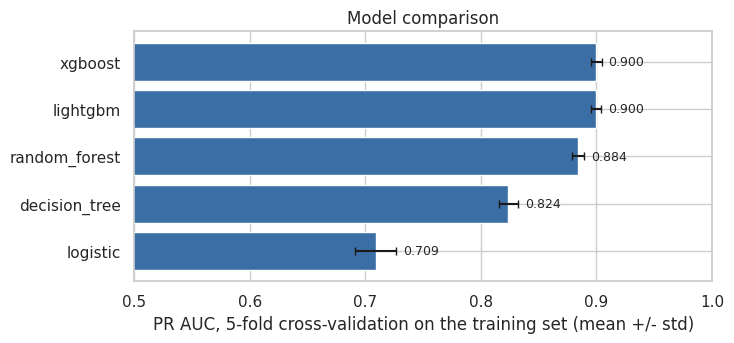

In [23]:
CHOSEN = "lightgbm"
print(f"rule pick in this run: {best} | chosen explicitly: {CHOSEN} (equivalent to {'xgboost' if CHOSEN == 'lightgbm' else 'lightgbm'} within noise)")

chosen_model = build_model(CHOSEN, "selected", n_jobs=1).fit(X_train, y_train)
chosen_scores = chosen_model.predict_proba(X_val)[:, 1]
chosen_metrics = classification_metrics(y_val, chosen_scores)

update_comparison_table(
    REPORTS / "model_comparison.csv", "lightgbm (default settings)", chosen_metrics,
    notes="issue 10: chosen model, selected features (loan_to_income replaces loan_percent_income)",
)
cv_table.drop(columns="fit_seconds_mean").round(4).rename_axis("model").to_csv(REPORTS / "cv_comparison.csv")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
t = cv_table.sort_values("pr_auc_mean")
ax.barh(t.index, t["pr_auc_mean"], xerr=t["pr_auc_std"], color="#3b6ea5", capsize=3)
for i, (m, sd) in enumerate(zip(t["pr_auc_mean"], t["pr_auc_std"])):
    ax.text(m + sd + 0.006, i, f"{m:.3f}", va="center", fontsize=9)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("PR AUC, 5-fold cross-validation on the training set (mean +/- std)")
ax.set_title("Model comparison")
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "model_cv_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

In [24]:
table = pd.read_csv(REPORTS / "model_comparison.csv")
print(comparison_to_markdown(table))
print()
print(cv_table_to_markdown(cv_table))

| Model | ROC AUC | PR AUC | KS | Brier | Recall | Precision |
|---|---|---|---|---|---|---|
| lightgbm (tuned, 40 Optuna trials) | 0.948 | 0.907 | 0.765 | 0.051 | 0.750 | 0.966 |
| constant prior (no model) | 0.500 | 0.219 | 0.000 | 0.171 | 0.000 | 0.000 |
| logistic regression (baseline) | 0.877 | 0.723 | 0.611 | 0.104 | 0.544 | 0.741 |
| logistic + loan_to_income (replaces loan_percent_income) | 0.878 | 0.726 | 0.609 | 0.103 | 0.550 | 0.744 |
| lightgbm (default settings) | 0.946 | 0.905 | 0.759 | 0.051 | 0.752 | 0.954 |

| Model | PR AUC | ROC AUC | KS | Brier |
|---|---|---|---|---|
| xgboost | 0.900 ± 0.004 | 0.946 ± 0.002 | 0.750 ± 0.008 | 0.054 ± 0.002 |
| lightgbm | 0.900 ± 0.004 | 0.944 ± 0.001 | 0.752 ± 0.012 | 0.054 ± 0.002 |
| random_forest | 0.884 ± 0.005 | 0.932 ± 0.002 | 0.735 ± 0.015 | 0.059 ± 0.002 |
| decision_tree | 0.824 ± 0.008 | 0.892 ± 0.005 | 0.679 ± 0.015 | 0.067 ± 0.003 |
| logistic | 0.709 ± 0.018 | 0.867 ± 0.008 | 0.583 ± 0.017 | 0.107 ± 0.003 |


## 5. Class imbalance (issue #11)

### Protocol (fixed before looking at any result)

- **Data and folds:** cleaned **training set only**, the same 5 stratified folds as before.
- **Models:** the baseline logistic regression and the chosen LightGBM (XGBoost is left out: its `scale_pos_weight` depends on each training fold, so it cannot be a fixed setting).
- **Strategies:** `none`; `class_weight` ("balanced"); `smote` (SMOTE-NC, 1:1, applied **only to the training part of each fold**: the pipeline resamples in `fit` and never in `predict`, so validation rows are never resampled).
- **Ranking quality:** PR AUC, ROC AUC, KS and the precision reachable at 80% recall.
- **Probabilities and operating point:** Brier score, mean predicted probability (the default rate is 21.9%), and recall and precision at the 0.5 reference threshold.
- **Adoption rule:** a strategy is adopted for a model only if its paired PR AUC gain over `none` is larger than the standard deviation of the paired differences, and its precision at 80% recall does not drop. Shifted probabilities or a different recall at 0.5 are **not** reasons to adopt: calibration (issue #14) and the cost-optimal threshold (issue #16) deal with those.
- **Why:** balancing mostly moves the operating point, and a threshold can do the same on an unweighted model. A last check below verifies this directly.

In [25]:
extra = {
    "p_at_r80": lambda yt, s: precision_at_recall(yt, s, 0.8),
    "recall_05": lambda yt, s: recall_score(yt, (s >= 0.5).astype(int), zero_division=0),
    "precision_05": lambda yt, s: precision_score(yt, (s >= 0.5).astype(int), zero_division=0),
    "mean_pred": lambda yt, s: s.mean(),
}
imb = {
    (m, st): cross_validate_model(build_imbalance_model(m, st, n_jobs=1), X_train, y_train, extra=extra)
    for m in ("logistic", "lightgbm") for st in IMBALANCE_STRATEGIES
}
cols = ["pr_auc", "roc_auc", "ks", "p_at_r80", "brier", "mean_pred", "recall_05", "precision_05"]
rows = []
for (m, st), sc in imb.items():
    row = {"model": m, "strategy": st}
    for c in cols:
        row[c + "_mean"], row[c + "_std"] = sc[c].mean(), sc[c].std(ddof=1)
    rows.append(row)
imb_table = pd.DataFrame(rows).set_index(["model", "strategy"])
display(imb_table[[f"{c}_{k}" for c in cols for k in ("mean", "std")]].round(4))
print(f"default rate in the training set: {y_train.mean():.4f}")
imb_table.round(4).to_csv(REPORTS / "imbalance_comparison.csv")

pr_auc_mean  pr_auc_std  roc_auc_mean  roc_auc_std  ks_mean  ks_std  p_at_r80_mean  p_at_r80_std  brier_mean  brier_std  \
model    strategy                                                                                                                                
logistic none               0.7089      0.0176        0.8675       0.0083   0.5832  0.0172         0.5019        0.0218      0.1067     0.0027   
         class_weight       0.7036      0.0162        0.8679       0.0076   0.5865  0.0152         0.5002        0.0190      0.1457     0.0031   
         smote              0.7012      0.0180        0.8654       0.0083   0.5799  0.0173         0.4939        0.0192      0.1406     0.0033   
lightgbm none               0.8998      0.0043        0.9443       0.0012   0.7521  0.0115         0.8077        0.0402      0.0540     0.0022   
         class_weight       0.8972      0.0041        0.9422       0.0011   0.7483  0.0107         0.7995        0.0295      0.0610     0.0017   
         smote              0.8968      0.0047        0.9429       0.0018   0.7478  0.0128         0.7900        0.0341      0.0552     0.0028   

                       mean_pred_mean  mean_pred_std  recall_05_mean  recall_05_std  precision_05_mean  precision_05_std  
model    strategy                                                                                                         
logistic none                  0.2188         0.0047          0.5169         0.0267             0.7470            0.0158  
         class_weight          0.3841         0.0041          0.7874         0.0120             0.5121            0.0102  
         smote                 0.3664         0.0032          0.7679         0.0150             0.5260            0.0129  
lightgbm none                  0.2081         0.0019          0.7314         0.0125             0.9566            0.0080  
         class_weight          0.2603         0.0014          0.7714         0.0124             0.8621            0.0091  
         smote                 0.2154         0.0030          0.7333         0.0175             0.9425            0.0110

default rate in the training set: 0.2187


In [26]:
rows, adopted = [], []
for m in ("logistic", "lightgbm"):
    for st in ("class_weight", "smote"):
        base_sc, cand_sc = imb[(m, "none")], imb[(m, st)]
        g = paired_gain(base_sc, cand_sc, "pr_auc")
        d80 = cand_sc["p_at_r80"].to_numpy() - base_sc["p_at_r80"].to_numpy()
        ok = g["mean_gain"] > g["std_gain"] and d80.mean() >= 0
        if ok:
            adopted.append((m, st))
        rows.append({"model": m, "strategy": st, "dPR AUC": g["mean_gain"], "sd": g["std_gain"], "folds better": f"{g['folds_improved']}/5",
                     "dPrecision@R80": d80.mean(), "adopted": ok})
display(pd.DataFrame(rows).set_index(["model", "strategy"]).round(4))
print("Strategies adopted by the rule:", adopted if adopted else "none")

dPR AUC      sd folds better  dPrecision@R80  adopted
model    strategy                                                           
logistic class_weight  -0.0054  0.0022          0/5         -0.0017    False
         smote         -0.0078  0.0019          0/5         -0.0081    False
lightgbm class_weight  -0.0026  0.0019          0/5         -0.0082    False
         smote         -0.0030  0.0031          0/5         -0.0177    False

Strategies adopted by the rule: none


### Check: the same operating point with a threshold on the unweighted model

In [27]:
y_arr = y_train.to_numpy()

def operating_point(scores, threshold):
    pred = scores >= threshold
    tp = (pred & (y_arr == 1)).sum()
    return tp / (y_arr == 1).sum(), tp / max(pred.sum(), 1)

grid = np.linspace(0.005, 0.995, 991)
rows = []
for m in ("lightgbm", "logistic"):
    oof_none = oof_proba(lambda: build_imbalance_model(m, "none", n_jobs=1), X_train, y_train)
    for st in ("class_weight", "smote"):
        oof_st = oof_proba(lambda: build_imbalance_model(m, st, n_jobs=1), X_train, y_train)
        rec, prec = operating_point(oof_st, 0.5)
        thr = min(grid, key=lambda t: abs(operating_point(oof_none, t)[0] - rec))
        rec_n, prec_n = operating_point(oof_none, thr)
        rows.append({"model": m, "strategy at threshold 0.5": st, "recall": rec, "precision": prec,
                     "unweighted: threshold": thr, "unweighted: recall": rec_n, "unweighted: precision": prec_n,
                     "precision gain of unweighted": prec_n - prec})
display(pd.DataFrame(rows).set_index(["model", "strategy at threshold 0.5"]).round(3))

recall  precision  unweighted: threshold  unweighted: recall  unweighted: precision  precision gain of unweighted
model    strategy at threshold 0.5                                                                                                                   
lightgbm class_weight                0.771      0.862                  0.309               0.771                  0.874                         0.012
         smote                       0.733      0.943                  0.487               0.734                  0.953                         0.010
logistic class_weight                0.787      0.512                  0.218               0.788                  0.511                        -0.001
         smote                       0.768      0.526                  0.237               0.767                  0.527                         0.001

### Decision: no class weights and no SMOTE

- **Ranking quality does not improve; it slightly worsens.** PR AUC, LightGBM: 0.8998 without balancing, 0.8972 with class weights (paired gain -0.0026, worse on 5 of 5 folds) and 0.8968 with SMOTE (-0.0030, worse on 5 of 5). Logistic regression: 0.709 without, 0.704 with class weights (-0.0054, 0 of 5 folds) and 0.701 with SMOTE (-0.0078, 0 of 5). ROC AUC and KS are essentially unchanged. Precision at 80% recall is the same within noise (differences between -0.002 and -0.018, with spreads of 0.006 to 0.05).
- **Probabilities get worse.** Brier score, LightGBM: 0.0540 without balancing, 0.0610 with class weights. Logistic regression: 0.107 without, 0.146 with class weights and 0.141 with SMOTE. The mean predicted probability moves away from the 21.9% default rate (logistic regression: 0.22 without, 0.38 with class weights, 0.37 with SMOTE).
- **What balancing really does is move the operating point at 0.5.** With class weights, LightGBM's recall at 0.5 rises from 0.731 to 0.771 and its precision falls from 0.957 to 0.862. The unweighted model reaches the same recall with a threshold of 0.31 and a **better** precision (0.874); against SMOTE the unweighted model is also slightly better (0.953 versus 0.943). For the logistic regression the two are equivalent (differences of 0.001).
- **Therefore the models stay unweighted.** The imbalance (21.9% defaults) is handled where it belongs: calibration of the probabilities (issue #14) and a decision threshold chosen from the cost matrix (issue #16).
- **Limits:** default hyperparameters, one resampling setting (1:1), and XGBoost not tested. Class weighting can be revisited cheaply as a hyperparameter at tuning time (issue #13).

## 6. Hyperparameter tuning (issue #13)

### Protocol

- **The search itself** is run by `scripts/tune_lightgbm.py` (about 2.5 minutes), not in this notebook: 40 trials of a seeded TPE sampler from Optuna, objective = mean PR AUC of the same 5 stratified folds as before (seed 42), **training set only**. The first trial is a starting point close to the default configuration. This notebook reads the saved results from `reports/tuning/`.
- **Model:** the chosen LightGBM. Search space below.
- **Why the gain needs a separate measurement:** the best of 40 trials is optimistically biased (the search picked the winner on these very folds). The gain is therefore measured on data the search did not optimize on: two **fresh fold splits** of the training set (seeds 7 and 123) and the **validation set** (a second use of the validation set, limited to these two models).
- **Adoption rule (the same as in issues #9 and #11):** adopt the tuned model only if its paired PR AUC gain on the fresh folds is larger than the standard deviation of the paired differences, for both seeds, and its validation PR AUC is not lower than the default model's.

In [28]:
space = pd.DataFrame(
    [{"parameter": k, "type": v[0], "range": (str(v[1]) if v[0] != "categorical" else str(v[1])) if v[0] == "categorical" else f"{v[1]} to {v[2]}"} for k, v in SPACE.items()]
).set_index("parameter")
display(space)

trials = pd.read_csv(REPORTS / "tuning" / "lightgbm_trials.csv")
best_params = load_best_params(REPORTS / "tuning" / "lightgbm_best_params.json")
default_cv = cv_res["lightgbm"]["pr_auc"].mean()

print(f"{len(trials)} trials | PR AUC: min {trials['pr_auc'].min():.4f}, median {trials['pr_auc'].median():.4f}, max {trials['pr_auc'].max():.4f}")
print(f"default LightGBM on the same folds: {default_cv:.4f} | start point of the search (trial 0): {trials.loc[0, 'pr_auc']:.4f}")
print("best parameters:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})
display(trials.sort_values("pr_auc", ascending=False).head(5).round(4).set_index("trial"))

,type,range
parameter,,
n_estimators,int,100 to 600
learning_rate,"float, log scale",0.02 to 0.2
num_leaves,"int, log scale",8 to 96
min_child_samples,int,5 to 80
subsample,float,0.6 to 1.0
colsample_bytree,float,0.5 to 1.0
reg_alpha,"float, log scale",0.001 to 10.0
reg_lambda,"float, log scale",0.001 to 10.0
class_weight,categorical,"[None, 'balanced']"


40 trials | PR AUC: min 0.8838, median 0.8993, max 0.9020
default LightGBM on the same folds: 0.8998 | start point of the search (trial 0): 0.8984
best parameters: {'n_estimators': 492, 'learning_rate': 0.1025, 'num_leaves': 10, 'min_child_samples': 27, 'subsample': 0.8886, 'colsample_bytree': 0.7491, 'reg_alpha': 0.0493, 'reg_lambda': 0.3189, 'class_weight': None}


,pr_auc,pr_auc_std,roc_auc,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,class_weight
trial,,,,,,,,,,,,
32,0.9020,0.0031,0.9474,492,0.1025,10,27,0.8886,0.7491,0.0493,0.3189,NaN
21,0.9020,0.0047,0.9465,442,0.0598,31,21,0.8344,0.6482,0.0082,0.2050,NaN
31,0.9017,0.0042,0.9465,479,0.1372,14,19,0.8807,0.5885,0.0296,0.3286,NaN
33,0.9012,0.0037,0.9465,446,0.1130,9,31,0.8954,0.7511,0.0308,0.1119,NaN
35,0.9007,0.0035,0.9465,508,0.0863,9,20,0.8648,0.7458,0.1692,0.3073,NaN


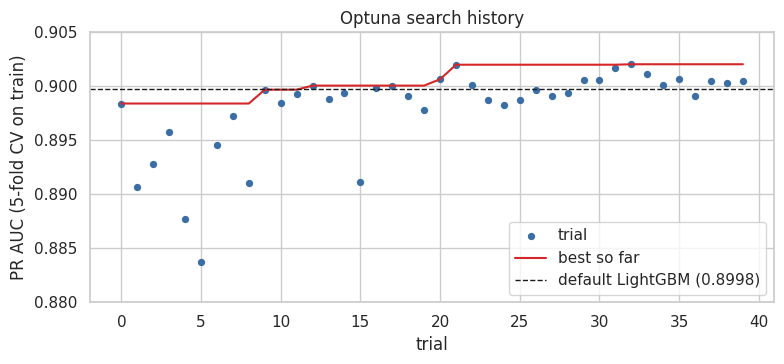

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(trials["trial"], trials["pr_auc"], s=18, color="#3b6ea5", label="trial")
ax.plot(trials["trial"], trials["pr_auc"].cummax(), color="#d62728", label="best so far")
ax.axhline(default_cv, color="k", linestyle="--", linewidth=1, label=f"default LightGBM ({default_cv:.4f})")
ax.set_ylim(0.88, 0.905)
ax.set_xlabel("trial")
ax.set_ylabel("PR AUC (5-fold CV on train)")
ax.set_title("Optuna search history")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "tuning_history.png", dpi=130, bbox_inches="tight")
plt.show()

In [30]:
cols = ["n_estimators", "learning_rate", "num_leaves", "min_child_samples", "subsample", "colsample_bytree", "reg_alpha", "reg_lambda"]
ranked = trials.sort_values("pr_auc")
worst8, best8 = ranked.head(8), ranked.tail(8)
print("5 worst trials:")
display(ranked.head(5)[["trial", "pr_auc"] + cols].round(3).set_index("trial"))
display(pd.DataFrame({"median of the 8 worst": worst8[cols].median(), "median of the 8 best": best8[cols].median()}).round(3))
print("trials with class weights: among the 8 worst", int(worst8["class_weight"].notna().sum()), "| among the 8 best", int(best8["class_weight"].notna().sum()))

5 worst trials:


,pr_auc,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda
trial,,,,,,,,,
5,0.884,161,0.063,8,74,0.704,0.831,0.018,0.120
4,0.888,404,0.030,9,77,0.986,0.904,0.017,0.002
1,0.891,287,0.179,49,50,0.662,0.578,0.002,2.915
8,0.891,486,0.032,8,66,0.883,0.865,1.216,0.002
15,0.891,569,0.078,15,24,0.727,0.774,7.919,0.118


,median of the 8 worst,median of the 8 best
n_estimators,405.000,479.000
learning_rate,0.070,0.108
num_leaves,15.500,11.500
min_child_samples,58.000,20.500
subsample,0.755,0.875
colsample_bytree,0.848,0.677
reg_alpha,0.017,0.040
reg_lambda,0.116,0.313


trials with class weights: among the 8 worst 2 | among the 8 best 0


### Gain on data the search did not optimize on

In [31]:
default_model = lambda: build_model("lightgbm", "selected", n_jobs=1)
tuned_model = lambda: build_tuned_model(best_params)

rows, fresh_ok = [], []
for seed in (7, 123):
    d = cross_validate_model(default_model(), X_train, y_train, random_state=seed)
    t = cross_validate_model(tuned_model(), X_train, y_train, random_state=seed)
    g = paired_gain(d, t, "pr_auc")
    fresh_ok.append(g["mean_gain"] > g["std_gain"])
    rows.append({
        "fold seed": seed,
        "default PR AUC": d["pr_auc"].mean(), "tuned PR AUC": t["pr_auc"].mean(),
        "paired gain": g["mean_gain"], "sd of paired diff": g["std_gain"], "folds better": f"{g['folds_improved']}/{g['n_folds']}",
        "gain > sd": g["mean_gain"] > g["std_gain"],
    })
display(pd.DataFrame(rows).set_index("fold seed").round(4))

,default PR AUC,tuned PR AUC,paired gain,sd of paired diff,folds better,gain > sd
fold seed,,,,,,
7,0.8986,0.9007,0.0021,0.0035,3/5,False
123,0.8989,0.9010,0.0021,0.0038,4/5,False


In [32]:
default_fit = default_model().fit(X_train, y_train)
tuned_fit = tuned_model().fit(X_train, y_train)
default_val = classification_metrics(y_val, default_fit.predict_proba(X_val)[:, 1])
tuned_val = classification_metrics(y_val, tuned_fit.predict_proba(X_val)[:, 1])
display(pd.DataFrame({"lightgbm default": default_val, "lightgbm tuned": tuned_val}).T[metric_cols].round(4))

adopt_tuned = all(fresh_ok) and tuned_val["pr_auc"] >= default_val["pr_auc"]
print(f"gain larger than the noise on both fold seeds: {all(fresh_ok)} | validation PR AUC not lower: {tuned_val['pr_auc'] >= default_val['pr_auc']}")
print("Decision by the rule:", "adopt the tuned model" if adopt_tuned else "keep the default LightGBM")

update_comparison_table(
    REPORTS / "model_comparison.csv", "lightgbm (tuned, 40 Optuna trials)", tuned_val,
    notes="issue 13: not adopted, gain within noise" if not adopt_tuned else "issue 13: adopted",
)

,roc_auc,pr_auc,ks,brier,recall,precision
lightgbm default,0.9459,0.9049,0.7595,0.0514,0.7525,0.9544
lightgbm tuned,0.9479,0.9071,0.7648,0.0511,0.7496,0.9664


gain larger than the noise on both fold seeds: False | validation PR AUC not lower: True
Decision by the rule: keep the default LightGBM


,model,split,roc_auc,pr_auc,ks,brier,recall,precision,threshold,notes
0,constant prior (no model),validation,0.5000,0.2188,0.0000,0.1709,0.0000,0.0000,0.5,same probability for everyone
1,logistic regression (baseline),validation,0.8767,0.7230,0.6107,0.1036,0.5437,0.7406,0.5,"linear preprocessing, default C=1, no class we..."
2,logistic + loan_to_income (replaces loan_perce...,validation,0.8779,0.7261,0.6089,0.1029,0.5501,0.7436,0.5,issue 9: recomputed ratio replaces the provide...
3,lightgbm (default settings),validation,0.9459,0.9049,0.7595,0.0514,0.7525,0.9544,0.5,"issue 10: chosen model, selected features (loa..."
4,"lightgbm (tuned, 40 Optuna trials)",validation,0.9479,0.9071,0.7648,0.0511,0.7496,0.9664,0.5,"issue 13: not adopted, gain within noise"


### Decision: keep the default LightGBM

- **The search finds a plateau.** Over 40 trials the best PR AUC is 0.9020 against 0.8998 for the default on the same folds, and the 8 best trials all lie between 0.9006 and 0.9020. The worst trials (down to 0.8838) are models that learn too little rather than too much: their median `min_child_samples` is 58 against about 20 for the best trials, with a lower learning rate (0.07 against 0.11) and a lower share of rows drawn per tree (0.76 against 0.88). None of the 10 best trials uses class weights, whereas 2 of the 8 worst do, which is consistent with issue #11.
- **Best configuration:** 492 trees, learning rate 0.10, 10 leaves, `min_child_samples` 27, `subsample` 0.89, `colsample_bytree` 0.75 and light L1/L2 regularization (0.05 and 0.32). It is simpler per tree than the default (10 leaves instead of 31) but has more trees (492 instead of 300).
- **The gain does not survive a fair measurement.** On fresh folds the paired PR AUC gain is +0.0021 for both seeds, against paired standard deviations of 0.0035 and 0.0038 (better on 3 of 5 and 4 of 5 folds): smaller than the noise. On the validation set the tuned model is slightly higher (PR AUC 0.9071 versus 0.9049, ROC AUC 0.948 versus 0.946, KS 0.765 versus 0.760), with the same Brier score. The direction is consistent across the three measurements, but each is within noise.
- **By the rule, the tuned model is not adopted.** The default LightGBM stays the reference model for calibration, thresholds and the final evaluation. Changing the rule now that the numbers are known would not be rigorous. The tuned parameters stay saved in `reports/tuning/lightgbm_best_params.json` and the row is recorded in the comparison table.
- **What this says:** hyperparameters matter little on this dataset, which fits the earlier observation that a few threshold rules already carry most of the signal. The validation set was used a second time here, limited to these two models.